Importiamo le librerie per calcolo numerico, elementi finiti, campionamento e grafici. Attiviamo il ricaricamento automatico dei moduli e importiamo il modello del mixer.

In [355]:
import numpy as np
import dlroms.fespaces as fe
from scipy.stats import qmc
import matplotlib.pyplot as plt

%load_ext autoreload
%autoreload 2
import MixerFunctions as mixer

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


### FOM Dataset

Generiamo 50 parametri di training con Latin Hypercube Sampling e 50 di test con campionamento uniforme nel dominio $[-5,5]^3$. I seed rendono riproducibili i campioni.

Il Latin Hypercube suddivide ogni coordinata in intervalli equiprobabili e usa un campione per intervallo, migliorando la copertura marginale rispetto a un campionamento casuale semplice. I campioni test sono generati separatamente e non vengono usati per costruire la base POD.

In [2]:
Ntrain = 50
Ntest = 50
nparams = 3

# Latin Hypercube Sampling for training
sampler = qmc.LatinHypercube(d=nparams, seed=42)
mu_train_unit = sampler.random(n=Ntrain)

# Map [0,1]^3 -> [-5,5]^3
mu_train = qmc.scale(
    mu_train_unit,
    l_bounds=[-5, -5, -5],
    u_bounds=[ 5,  5,  5]
)

# Uniform sampling for testing data
rng = np.random.default_rng(123)

mu_test = rng.uniform(
    low=-5,
    high=5,
    size=(Ntest, nparams)
)

mu_test.shape

mu_train.shape, mu_test.shape


((50, 3), (50, 3))

Risolviamo il modello completo (FOM) per il primo parametro di training, ottenendo il vettore della concentrazione.

Il modello stazionario discretizza $-\varepsilon\Delta u+\mathbf b(\mu)\cdot\nabla u=0$, con $\varepsilon=0.005$ e $\mathbf b(\mu)=\mathbf b_0+c_1\mathbf b_1+c_2\mathbf b_2+c_3\mathbf b_3$. I campi di velocità sono precalcolati tramite Stokes. Sul bordo sinistro imponiamo $u=g(y)=e^{-25(y-1)^2}$; sugli altri bordi la formulazione della concentrazione lascia la condizione naturale di flusso diffusivo nullo. Per test $v$ nulli sul bordo di Dirichlet, la forma debole è $\varepsilon\int_\Omega\nabla u\cdot\nabla v+\int_\Omega(\mathbf b\cdot\nabla u)v=0$.

In [ ]:
u = mixer.FOMsolver(mu_train[0])

array([5.62442465e-01, 5.62736064e-01, 5.62404155e-01, ...,
       1.38879437e-11, 1.58939098e-10, 1.60523106e-09])

Calcoliamo tutte le soluzioni FOM di training e i rispettivi tempi. Ogni colonna di `U_train` contiene uno snapshot; le righe corrispondono ai gradi di libertà dello spazio agli elementi finiti.

In [4]:
Nh = mixer.Vh.dim()

import time

U_train = np.zeros((Nh, Ntrain))
times_train = np.zeros(Ntrain)

for i, mu in enumerate(mu_train):
    print(f"Training FOM {i+1:02d}/{Ntrain}", end="")

    tic = time.perf_counter()

    U_train[:, i] = mixer.FOMsolver(mu)

    times_train[i] = time.perf_counter() - tic

    print(f" - {times_train[i]:.3f} s")

Training FOM 01/50 - 0.247 s
Training FOM 02/50 - 0.200 s
Training FOM 03/50 - 0.314 s
Training FOM 04/50 - 0.164 s
Training FOM 05/50 - 0.183 s
Training FOM 06/50 - 0.181 s
Training FOM 07/50 - 0.188 s
Training FOM 08/50 - 0.156 s
Training FOM 09/50 - 0.183 s
Training FOM 10/50 - 0.185 s
Training FOM 11/50 - 0.172 s
Training FOM 12/50 - 0.178 s
Training FOM 13/50 - 0.134 s
Training FOM 14/50 - 0.182 s
Training FOM 15/50 - 0.192 s
Training FOM 16/50 - 0.222 s
Training FOM 17/50 - 0.216 s
Training FOM 18/50 - 0.220 s
Training FOM 19/50 - 0.159 s
Training FOM 20/50 - 0.166 s
Training FOM 21/50 - 0.169 s
Training FOM 22/50 - 0.262 s
Training FOM 23/50 - 0.178 s
Training FOM 24/50 - 0.152 s
Training FOM 25/50 - 0.145 s
Training FOM 26/50 - 0.139 s
Training FOM 27/50 - 0.148 s
Training FOM 28/50 - 0.142 s
Training FOM 29/50 - 0.142 s
Training FOM 30/50 - 0.149 s
Training FOM 31/50 - 0.213 s
Training FOM 32/50 - 0.236 s
Training FOM 33/50 - 0.154 s
Training FOM 34/50 - 0.171 s
Training FOM 3

Controlliamo le dimensioni della matrice degli snapshot di training: numero di gradi di libertà per numero di campioni.

In [5]:
print(U_train.shape)

(2763, 50)


Costruiamo gli snapshot FOM di test e misuriamo i tempi di soluzione. Questi campioni serviranno a valutare il modello ridotto.

In [6]:
U_test = np.zeros((Nh, Ntest))
times_test = np.zeros(Ntest)

for i, mu in enumerate(mu_test):
    print(f"Test FOM {i+1:02d}/{Ntest}", end="")

    tic = time.perf_counter()

    U_test[:, i] = mixer.FOMsolver(mu)

    times_test[i] = time.perf_counter() - tic

    print(f" - {times_test[i]:.3f} s")

Test FOM 01/50 - 0.281 s
Test FOM 02/50 - 0.147 s
Test FOM 03/50 - 0.143 s
Test FOM 04/50 - 0.128 s
Test FOM 05/50 - 0.129 s
Test FOM 06/50 - 0.144 s
Test FOM 07/50 - 0.134 s
Test FOM 08/50 - 0.135 s
Test FOM 09/50 - 0.127 s
Test FOM 10/50 - 0.242 s
Test FOM 11/50 - 0.174 s
Test FOM 12/50 - 0.130 s
Test FOM 13/50 - 0.118 s
Test FOM 14/50 - 0.111 s
Test FOM 15/50 - 0.109 s
Test FOM 16/50 - 0.113 s
Test FOM 17/50 - 0.109 s
Test FOM 18/50 - 0.125 s
Test FOM 19/50 - 0.103 s
Test FOM 20/50 - 0.096 s
Test FOM 21/50 - 0.100 s
Test FOM 22/50 - 0.096 s
Test FOM 23/50 - 0.114 s
Test FOM 24/50 - 0.110 s
Test FOM 25/50 - 0.130 s
Test FOM 26/50 - 0.136 s
Test FOM 27/50 - 0.151 s
Test FOM 28/50 - 0.170 s
Test FOM 29/50 - 0.153 s
Test FOM 30/50 - 0.141 s
Test FOM 31/50 - 0.122 s
Test FOM 32/50 - 0.146 s
Test FOM 33/50 - 0.149 s
Test FOM 34/50 - 0.125 s
Test FOM 35/50 - 0.129 s
Test FOM 36/50 - 0.126 s
Test FOM 37/50 - 0.129 s
Test FOM 38/50 - 0.114 s
Test FOM 39/50 - 0.118 s
Test FOM 40/50 - 0.111 s


Riassumiamo il costo computazionale del FOM sui campioni di test tramite il tempo medio e il tempo totale.

In [7]:
print(f"Average FOM time: {times_test.mean():.4f} s")
print(f"Total FOM time:   {times_test.sum():.2f} s")

Average FOM time: 0.1299 s
Total FOM time:   6.49 s


Controlliamo dimensioni e valori estremi di una soluzione FOM e visualizziamo la concentrazione sul dominio.

Nh = 2763
mu = [-0.15479121  2.31222431 -2.37171958]
u shape = (2763,)
u min = 1.3887943746404563e-11
u max = 1.0


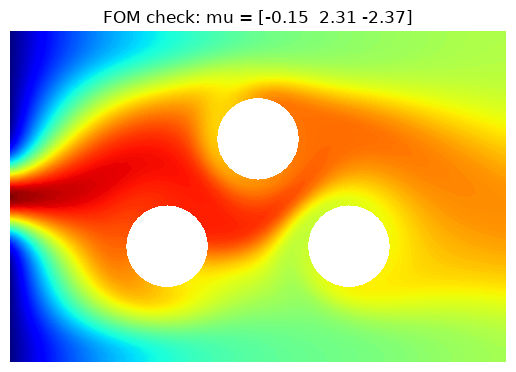

In [8]:
print("Nh =", mixer.Vh.dim())
print("mu =", mu_train[0])

u_check = mixer.FOMsolver(mu_train[0])

print("u shape =", u_check.shape)
print("u min =", u_check.min())
print("u max =", u_check.max())

fe.plot(u_check, mixer.Vh)
plt.title(f"FOM check: mu = {np.round(mu_train[0], 2)}")
plt.show()

Salviamo parametri, snapshot e tempi in un archivio NumPy, così da poterli riutilizzare senza ricalcolare il dataset.

In [9]:
np.savez(
    "FOMdata_assignment1.npz",

    mu_train=mu_train,
    U_train=U_train,

    mu_test=mu_test,
    U_test=U_test,

    times_train=times_train,
    times_test=times_test
)

Ricarichiamo il dataset salvato e ripristiniamo le variabili di training e test.

In [369]:
U_train[:, 0]

array([5.62442465e-01, 5.62736064e-01, 5.62404155e-01, ...,
       1.38879437e-11, 1.58939098e-10, 1.60523106e-09])

In [356]:
data = np.load("FOMdata_assignment1.npz")

mu_train = data["mu_train"]
U_train = data["U_train"]

mu_test = data["mu_test"]
U_test = data["U_test"]

times_train = data["times_train"]
times_test = data["times_test"]

### Handling Dirichlet condition

Calcoliamo una soluzione di riferimento $u_s$ per $\mu=(0,0,0)$. Questa soddisfa la stessa condizione di Dirichlet delle altre soluzioni e verrà usata come lifting.

Il lifting trasforma il problema con dato al bordo non nullo in uno per $w_\mu=u_\mu-u_s$ con dato omogeneo. Con sorgente nulla, le equazioni sui DOF liberi diventano $A(\mu)w_\mu=-A(\mu)u_s$. Poiché il dato al bordo non dipende dai parametri, un unico lifting è sufficiente.

In [357]:
mu_special = np.array([0.0, 0.0, 0.0])

u_special = mixer.FOMsolver(mu_special)

Visualizziamo la soluzione di riferimento scelta per il lifting.

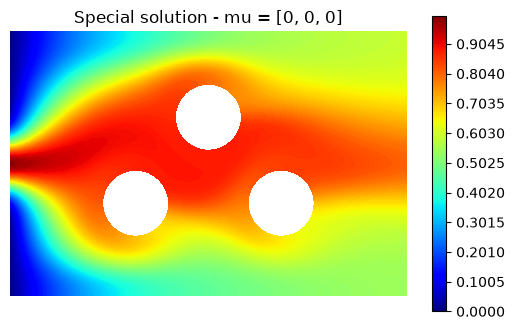

In [372]:
fe.plot(u_special, mixer.Vh, colorbar=True, vmin=u_special.min(), vmax=u_special.max())
plt.title("Special solution - mu = [0, 0, 0]")
plt.show()

Sottraiamo $u_s$ da ogni snapshot di training: $w_\mu=u_\mu-u_s$. Le differenze soddisfano una condizione di Dirichlet omogenea sul bordo sinistro.

In [359]:
W_train = U_train - u_special[:, None]

Verifichiamo su uno snapshot che $u_\mu=u_s+w_\mu$ e confrontiamo graficamente la soluzione originale, il lifting e la differenza.

mu = [ 0.37  -1.939 -1.489]
Reconstruction error: 0.0


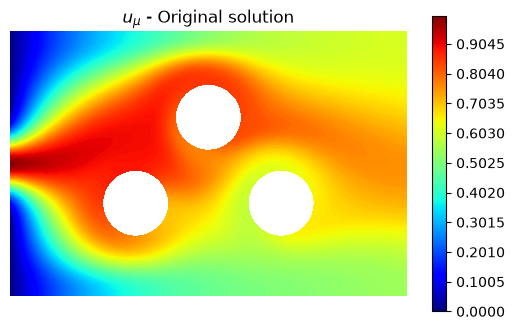

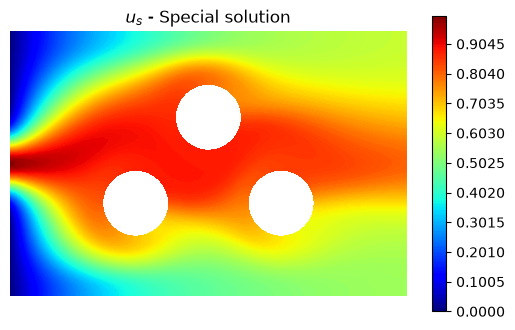

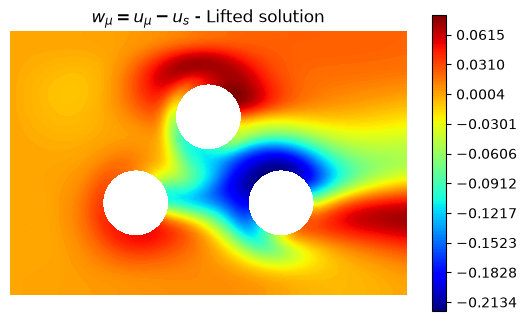

In [373]:
i = 30

mu = mu_train[i]
u_mu = U_train[:, i]
w_mu = W_train[:, i]

print("mu =", np.round(mu, 3))

print(
    "Reconstruction error:",
    np.linalg.norm(u_mu - (u_special + w_mu))
)

plt.figure()
fe.plot(u_mu, mixer.Vh, colorbar=True, vmin=u_mu.min(), vmax=u_mu.max())
plt.title(r"$u_\mu$ - Original solution")
plt.show()

plt.figure()
fe.plot(u_special, mixer.Vh, colorbar=True, vmin=u_special.min(), vmax=u_special.max())
plt.title(r"$u_s$ - Special solution")
plt.show()

plt.figure()
fe.plot(w_mu, mixer.Vh, colorbar=True, vmin=w_mu.min(), vmax=w_mu.max())
plt.title(r"$w_\mu = u_\mu - u_s$ - Lifted solution")
plt.show()

## SVD

Calcoliamo la SVD degli snapshot con condizione omogenea. Le colonne di `U_pod` sono i modi POD, ortonormali rispetto al prodotto scalare euclideo, ordinati per importanza tramite i valori singolari.

Scriviamo $W=U\Sigma Z^T$ e scegliamo $V_N=U[:,1:N]$. Questa base minimizza l'errore quadratico totale di proiezione degli snapshot fra tutte le basi euclidee ortonormali di dimensione $N$: $\|W-V_NV_N^TW\|_F^2=\sum_{i>N}\sigma_i^2$. La SVD qui non usa una matrice di massa, quindi l'ottimalità riguarda i vettori dei DOF e non direttamente la norma continua $L^2(\Omega)$.

In [398]:
U_pod, singular_values, VT = np.linalg.svd(
    W_train,
    full_matrices=False
)

print("W_train:", W_train.shape)
print("U_pod:", U_pod.shape)
print("singular_values:", singular_values.shape)
print("VT:", VT.shape)

W_train: (2763, 50)
U_pod: (2763, 50)
singular_values: (50,)
VT: (50, 50)


#### Decadimento dei valori singolari

Tracciamo i valori singolari in scala logaritmica per valutare quanto rapidamente diminuisce il contributo dei modi successivi.

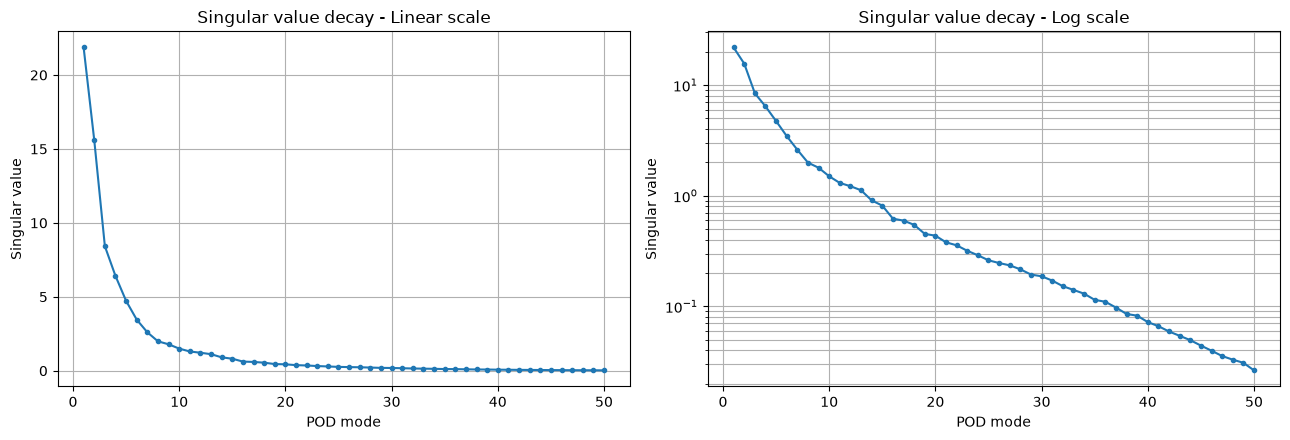

In [423]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))

modes = np.arange(1, len(singular_values) + 1)

# Linear scale
ax[0].plot(
    modes,
    singular_values,
    "o-",
    markersize=3
)

ax[0].set_xlabel("POD mode")
ax[0].set_ylabel("Singular value")
ax[0].set_title("Singular value decay - Linear scale")
ax[0].grid(True)


# Logarithmic scale
ax[1].semilogy(
    modes,
    singular_values,
    "o-",
    markersize=3
)

ax[1].set_xlabel("POD mode")
ax[1].set_ylabel("Singular value")
ax[1].set_title("Singular value decay - Log scale")
ax[1].grid(True, which="both")

plt.tight_layout()
plt.show()

Calcoliamo la frazione cumulativa di energia degli snapshot, usando i quadrati dei valori singolari, e stampiamo quella catturata dai primi dieci modi.

La frazione conservata è $E_N=\sum_{i\le N}\sigma_i^2/\sum_i\sigma_i^2$. Qui «energia» indica il contenuto quadratico degli snapshot, non un'energia fisica. L'errore relativo in norma di Frobenius della matrice proiettata è $\sqrt{1-E_N}$, non $1-E_N$.

In [400]:
N_energy = 10
energy = np.cumsum(singular_values**2) / np.sum(singular_values**2)
for i in range(N_energy):
    print(
        f"N = {i+1:2d} | "
        f"energy = {100*energy[i]:.6f}%"
    )

N =  1 | energy = 53.589099%
N =  2 | energy = 80.859757%
N =  3 | energy = 88.813050%
N =  4 | energy = 93.419929%
N =  5 | energy = 95.923073%
N =  6 | energy = 97.262108%
N =  7 | energy = 98.019794%
N =  8 | energy = 98.463495%
N =  9 | energy = 98.822217%
N = 10 | energy = 99.073362%


Determiniamo quanti modi POD servono per raggiungere ciascuna soglia di energia indicata.

Le soglie controllano l'errore aggregato di rappresentazione del training, non l'errore massimo sui test né quello dell'obiettivo. Inoltre il ciclo sovrascrive `N`: la base e gli operatori già calcolati non si aggiornano automaticamente.

In [401]:
thresholds = [0.95, 0.99, 0.999, 0.9999, 0.99999]

for threshold in thresholds:
    N = np.searchsorted(energy, threshold) + 1
    
    print(
        f"{100*threshold:.3f}% energy -> "
        f"N = {N}"
    )

95.000% energy -> N = 5
99.000% energy -> N = 10
99.900% energy -> N = 21
99.990% energy -> N = 34
99.999% energy -> N = 44


Selezioniamo i primi 20 modi e proiettiamo il primo snapshot omogeneo sulla loro base. Misuriamo l’errore relativo di proiezione in norma euclidea.

In [420]:
# Lifted test snapshots
W_test = U_test - u_special[:, None]

N_values = np.arange(1, U_pod.shape[1] + 1)

mean_proj_error_train = []
mean_proj_error_test = []

for N in N_values:

    V = U_pod[:, :N]

    # -------------------------
    # Training set
    # -------------------------
    errors_train = []

    for j in range(W_train.shape[1]):

        w = W_train[:, j]
        w_proj = V @ (V.T @ w)

        error = (
            np.linalg.norm(w - w_proj)
            / np.linalg.norm(w)
        )

        errors_train.append(error)

    mean_proj_error_train.append(
        100 * np.mean(errors_train)
    )

    # -------------------------
    # Test set
    # -------------------------
    errors_test = []

    for j in range(W_test.shape[1]):

        w = W_test[:, j]
        w_proj = V @ (V.T @ w)

        error = (
            np.linalg.norm(w - w_proj)
            / np.linalg.norm(w)
        )

        errors_test.append(error)

    mean_proj_error_test.append(
        100 * np.mean(errors_test)
    )

mean_proj_error_train = np.array(mean_proj_error_train)
mean_proj_error_test = np.array(mean_proj_error_test)

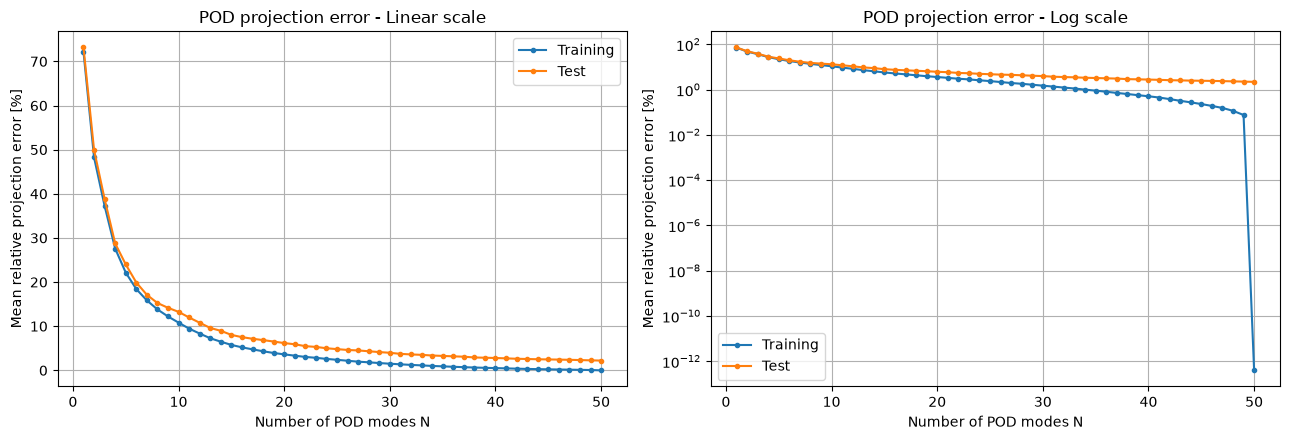

In [422]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))

# --------------------------------------------------
# Linear scale
# --------------------------------------------------

ax[0].plot(
    N_values,
    mean_proj_error_train,
    marker='o',
    markersize=3,
    label='Training'
)

ax[0].plot(
    N_values,
    mean_proj_error_test,
    marker='o',
    markersize=3,
    label='Test'
)

ax[0].set_xlabel('Number of POD modes N')
ax[0].set_ylabel('Mean relative projection error [%]')
ax[0].set_title('POD projection error - Linear scale')

ax[0].grid(True)
ax[0].legend()


# --------------------------------------------------
# Logarithmic scale
# --------------------------------------------------

ax[1].semilogy(
    N_values,
    mean_proj_error_train,
    marker='o',
    markersize=3,
    label='Training'
)

ax[1].semilogy(
    N_values,
    mean_proj_error_test,
    marker='o',
    markersize=3,
    label='Test'
)

ax[1].set_xlabel('Number of POD modes N')
ax[1].set_ylabel('Mean relative projection error [%]')
ax[1].set_title('POD projection error - Log scale')

ax[1].grid(True, which='both')
ax[1].legend()

plt.tight_layout()
plt.show()

Visualizziamo la frazione di energia scartata al crescere del numero di modi, per valutare l’effetto del troncamento POD.

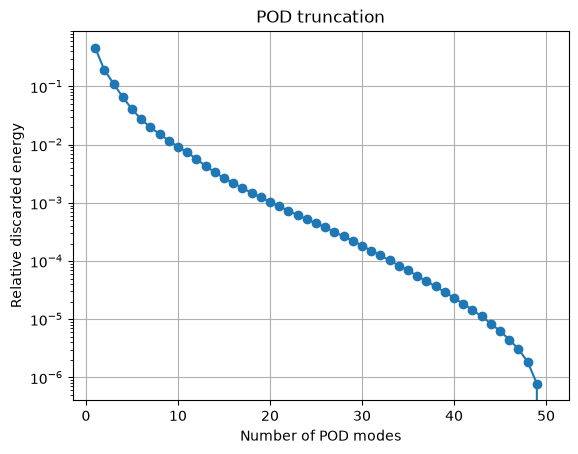

In [ ]:
lost_energy = 1 - energy

plt.figure()

plt.semilogy(
    np.arange(1, len(lost_energy) + 1),
    lost_energy,
    "o-"
)

plt.xlabel("Number of POD modes")
plt.ylabel("Relative discarded energy")
plt.title("POD truncation")
plt.grid(True)
plt.show()

Visualizziamo sul dominio i primi tre modi POD per osservare le strutture spaziali principali degli snapshot omogenei.

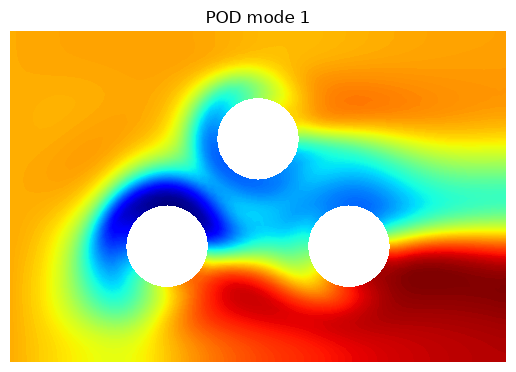

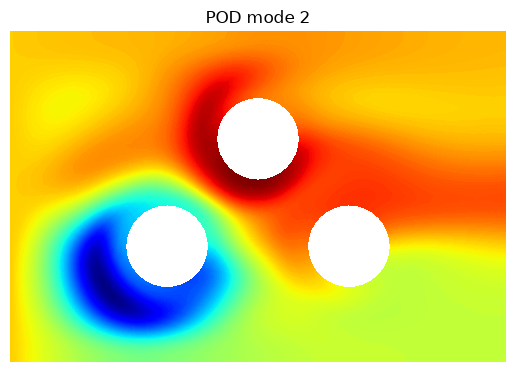

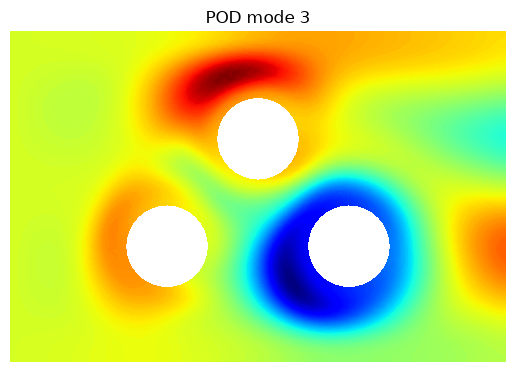

In [409]:
# Visualize the modes
for i in range(3):

    plt.figure()

    fe.plot(U_pod[:, i], mixer.Vh)

    plt.title(f"POD mode {i+1}")

    plt.show()

## Galerkin

Usiamo la condizione di Dirichlet di FEniCS per individuare i gradi di libertà sul bordo sinistro. Gli indici vengono memorizzati in `dirichlet_dofs` per eventuali operazioni sul bordo.

In [424]:
from fenics import DirichletBC, Constant

bc0 = DirichletBC(
    mixer.Vh,
    Constant(0.0),
    lambda x, on_boundary: on_boundary and mixer.left(x)
)

dirichlet_dofs = np.array(
    list(bc0.get_boundary_values().keys()),
    dtype=int
)

print("Number of Dirichlet DOFs:", len(dirichlet_dofs))

Number of Dirichlet DOFs: 41


Assembliamo gli operatori della decomposizione affine $A(\mu)=A_0+c_1A_1+c_2A_2+c_3A_3$. $A_0$ comprende diffusione e flusso di ingresso; gli altri operatori descrivono i contributi dei tre cilindri.

In [425]:
A0, A1, A2, A3 = mixer.assemble_affine_operators()

Controlliamo le dimensioni e il tipo degli operatori completi appena assemblati.

In [426]:
print(A0.shape)
print(A1.shape)
print(A2.shape)
print(A3.shape)
print(type(A0))

(2763, 2763)
(2763, 2763)
(2763, 2763)
(2763, 2763)
<class 'scipy.sparse._csr.csr_matrix'>


Fissiamo a 20 la dimensione ridotta e costruiamo la base `V` con i primi 20 modi POD.

In [427]:
N = 20

V = U_pod[:, :N]

Proiettiamo ogni operatore sulla base POD con $A_{i,N}=V^T A_i V$. Queste matrici ridotte vengono precalcolate nella fase offline.

Ponendo $u_N=u_s+V_Na_N$, la condizione Galerkin impone $V_N^T[A(\mu)(u_s+V_Na_N)]=0$. Ne segue $V_N^TA(\mu)V_Na_N=-V_N^TA(\mu)u_s$. I modi derivati dagli snapshot omogenei appartengono allo spazio dei test con traccia nulla sul bordo sinistro. La decomposizione affine consente di proiettare una sola volta gli operatori e di combinarli online tramite i parametri.

In [428]:
A0N = V.T @ A0 @ V
A1N = V.T @ A1 @ V
A2N = V.T @ A2 @ V
A3N = V.T @ A3 @ V

Controlliamo che la matrice proiettata abbia dimensioni $N \times N$.

In [429]:
print(A0N.shape)

(20, 20)


Calcoliamo il contributo del lifting al termine noto ridotto associato ad $A_0$: $f_{0,N}=-V^T A_0u_s$, e ne stampiamo la norma.

Dato che $u_s$ è la soluzione per $\mu=0$, il residuo di $A_0u_s$ sui test ammissibili è teoricamente nullo. La norma di $f_{0,N}$ dovrebbe quindi risultare piccola, entro gli errori numerici, quando base e assemblaggio sono coerenti.

In [430]:
f0N = -V.T @ (A0 @ u_special)

print("||f0N|| =", np.linalg.norm(f0N))

||f0N|| = 1.1235416548299292e-17


Calcoliamo gli altri tre contributi del lifting al termine noto ridotto: $f_{i,N}=-V^T A_i u_s$.

In [431]:
f1N = -V.T @ (A1 @ u_special)
f2N = -V.T @ (A2 @ u_special)
f3N = -V.T @ (A3 @ u_special)
print(f1N.shape)

(20,)


Controlliamo nuovamente la norma del contributo di $A_0u_s$ proiettato sulla base ridotta; il valore coincide con la norma di `f0N`.

In [432]:
np.linalg.norm(V.T @ (A0 @ u_special))

1.1235416548299292e-17

Per il parametro corrente `mu`, combiniamo gli operatori e i termini noti precalcolati per ottenere il sistema ridotto $A_N(\mu)a_N=f_N(\mu)$.

In [433]:
c1, c2, c3 = mu

AN = (
    A0N
    + c1*A1N
    + c2*A2N
    + c3*A3N
)

fN = (
    f0N
    + c1*f1N
    + c2*f2N
    + c3*f3N
)

Risolviamo il sistema ridotto, ricostruiamo la parte omogenea $w_{ROM}=Va_N$ e aggiungiamo il lifting per ottenere $u_{ROM}=u_s+Va_N$.

In [434]:
aN = np.linalg.solve(AN, fN)
w_rom = V @ aN
u_rom = u_special + w_rom

Raccogliamo assemblaggio e soluzione del sistema ridotto nella funzione `RBsolver(mu)`, che restituisce la concentrazione ricostruita per un parametro assegnato.

In [435]:
def RBsolver(mu):

    c1, c2, c3 = mu

    AN = (
        A0N
        + c1*A1N
        + c2*A2N
        + c3*A3N
    )

    fN = (
        f0N
        + c1*f1N
        + c2*f2N
        + c3*f3N
    )

    aN = np.linalg.solve(AN, fN)

    u_rom = u_special + V @ aN

    return u_rom

Valutiamo il modello ridotto sul primo parametro di test e calcoliamo l’errore relativo rispetto allo snapshot FOM in norma euclidea.

La norma usata è quella euclidea dei coefficienti FEM. Una misura discreta della norma $L^2$ richiederebbe la matrice di massa $M$, tramite $\|e\|_M=\sqrt{e^TMe}$. L'errore rispetto al FOM misura la riduzione del modello; non include una stima dell'errore di discretizzazione rispetto alla PDE continua.

In [436]:
mu = mu_test[0]

u_fom = U_test[:, 0]
u_rom = RBsolver(mu)
rel_error = (
    np.linalg.norm(u_fom - u_rom)
    / np.linalg.norm(u_fom)
)

print("mu =", mu)
print("Relative error =", rel_error)

mu = [ 1.82351863 -4.46178981 -2.79640127]
Relative error = 0.009214865310361933


Confrontiamo graficamente la soluzione FOM, la soluzione ROM e la loro differenza sul dominio.

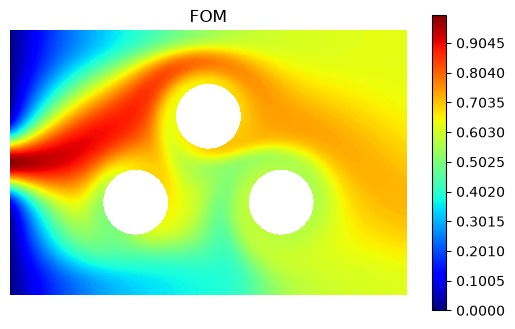

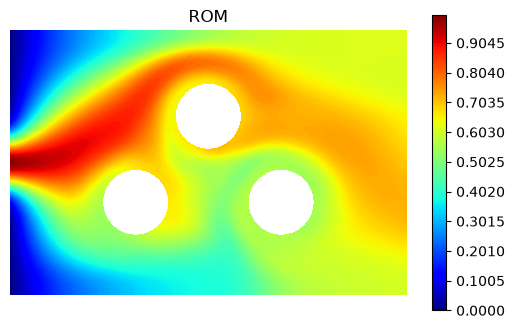

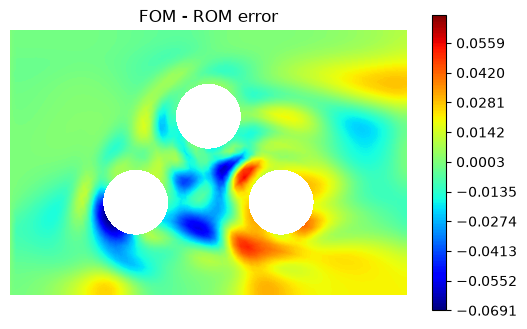

In [470]:
plt.figure()
fe.plot(u_fom, mixer.Vh, colorbar=True)
plt.title("FOM")
plt.show()

plt.figure()
fe.plot(u_rom, mixer.Vh, colorbar=True)
plt.title("ROM")
plt.show()

plt.figure()
fe.plot((u_fom - u_rom)/np.abs(u_fom), mixer.Vh, colorbar=True, vmax=np.max(np.abs(u_fom - u_rom)/np.abs(u_fom)), vmin=-np.max(np.abs(u_fom - u_rom)/np.abs(u_fom)))
plt.title("FOM - ROM error")
plt.show()

### Costruzione coerente del ROM

`build_ROM(N)` costruisce la base $V_N$, gli operatori $A_{i,N}=V_N^T A_iV_N$ e i termini $f_{i,N}=-V_N^TA_iu_s$, quindi restituisce tre funzioni: coefficienti, ricostruzione del campo e valutazione dell'obiettivo. Le funzioni conservano gli operatori locali della stessa costruzione, evitando di mescolare dimensioni diverse quando il valore globale di `N` cambia.

Per ogni parametro risolviamo $A_N(\mu)a_N=f_N(\mu)$ e ricostruiamo $u_N=u_s+V_Na_N$. La quantità di interesse è $J_N(\mu)=u_N(x_0;\mu)$, con $x_0=(1.5,0.25)$. In questa implementazione l'obiettivo ricostruisce il campo completo prima della valutazione FEM: anche questo passaggio ha un costo dipendente da $N_h$.

In [438]:
from fenics import Point

x0 = Point(1.5, 0.25)

def build_ROM(N):

    V = U_pod[:, :N]

    # Reduced affine matrices
    A0N = V.T @ A0 @ V
    A1N = V.T @ A1 @ V
    A2N = V.T @ A2 @ V
    A3N = V.T @ A3 @ V

    # Reduced affine RHS
    f0N = -V.T @ (A0 @ u_special)
    f1N = -V.T @ (A1 @ u_special)
    f2N = -V.T @ (A2 @ u_special)
    f3N = -V.T @ (A3 @ u_special)

    def coefficients(mu):

        c1, c2, c3 = mu

        AN = (
            A0N
            + c1*A1N
            + c2*A2N
            + c3*A3N
        )

        fN = (
            f0N
            + c1*f1N
            + c2*f2N
            + c3*f3N
        )

        return np.linalg.solve(AN, fN)

    def solver(mu):

        aN = coefficients(mu)

        return u_special + V @ aN

    def objective(mu):

        # Reconstruct ROM solution
        u_rom = solver(mu)

        # Convert the COMPLETE vector to a FEM function
        u_rom_fun = fe.asfunction(u_rom, mixer.Vh)

        return u_rom_fun(x0)

    return solver, coefficients, objective

### Validazione al variare della dimensione ridotta

Per ogni dimensione ricostruiamo un ROM e lo valutiamo sugli stessi campioni di test. Misuriamo $e_j(N)=100\,\|u_h(\mu_j)-u_N(\mu_j)\|_2/\|u_h(\mu_j)\|_2$, salvando errore medio, massimo e tempi. Gli errori memorizzati sono già percentuali.

Questo confronto misura la generalizzazione fuori dal training. Aumentare $N$ migliora la capacità di rappresentazione della base, ma l'errore Galerkin sui singoli test non è necessariamente monotono. I tempi includono soluzione ridotta e ricostruzione del campo, escludendo la costruzione offline del ROM.

In [439]:
N_values = [5, 10, 15, 20, 25, 30, 35, 40]

results = {}

for N in N_values:

    RBsolver, RBcoefficients, objective = build_ROM(N)

    errors = np.zeros(Ntest)
    times_rom = np.zeros(Ntest)

    for j, mu in enumerate(mu_test):

        tic = time.perf_counter()

        u_rom = RBsolver(mu)

        times_rom[j] = time.perf_counter() - tic

        errors[j] = 100 * (
            np.linalg.norm(U_test[:, j] - u_rom)
            / np.linalg.norm(U_test[:, j])

        )

    results[N] = {
        "errors": errors,
        "times": times_rom,
        "mean_error": errors.mean(),
        "max_error": errors.max(),
        "mean_time": times_rom.mean()
    }

    print(
        f"N={N:2d} | "
        f"mean error={errors.mean():.3e} | "
        f"max error={errors.max():.3e} | "
        f"ROM time={times_rom.mean():.3e} s"
    )

N= 5 | mean error=4.333e+00 | max error=8.730e+00 | ROM time=2.589e-05 s
N=10 | mean error=2.573e+00 | max error=5.229e+00 | ROM time=4.931e-05 s
N=15 | mean error=1.556e+00 | max error=4.043e+00 | ROM time=3.395e-05 s
N=20 | mean error=1.221e+00 | max error=3.420e+00 | ROM time=4.573e-05 s
N=25 | mean error=9.175e-01 | max error=2.960e+00 | ROM time=4.668e-05 s
N=30 | mean error=7.926e-01 | max error=2.678e+00 | ROM time=4.727e-05 s
N=35 | mean error=6.469e-01 | max error=1.911e+00 | ROM time=8.322e-05 s
N=40 | mean error=5.467e-01 | max error=1.578e+00 | ROM time=7.022e-05 s


Cella vuota disponibile per ulteriori controlli; non esegue operazioni.

**Accelerazione rispetto al FOM.** Calcoliamo $S(N)=\overline{t}_{FOM}/\overline{t}_{ROM}(N)$. Un valore maggiore di uno indica un risparmio per singola valutazione. Il rapporto non comprende il costo iniziale degli snapshot, della SVD e delle proiezioni: tale investimento si ammortizza quando si eseguono molte valutazioni online.

In [440]:
fom_time = times_test.mean()

for N in N_values:

    rom_time = results[N]["mean_time"]
    speedup = fom_time / rom_time

    print(
        f"N={N:2d} | "
        f"FOM={fom_time:.4e}s | "
        f"ROM={rom_time:.4e}s | "
        f"speed-up={speedup:.1f}x"
    )

N= 5 | FOM=1.2985e-01s | ROM=2.5893e-05s | speed-up=5015.1x
N=10 | FOM=1.2985e-01s | ROM=4.9309e-05s | speed-up=2633.5x
N=15 | FOM=1.2985e-01s | ROM=3.3953e-05s | speed-up=3824.4x
N=20 | FOM=1.2985e-01s | ROM=4.5730e-05s | speed-up=2839.6x
N=25 | FOM=1.2985e-01s | ROM=4.6679e-05s | speed-up=2781.8x
N=30 | FOM=1.2985e-01s | ROM=4.7273e-05s | speed-up=2746.8x
N=35 | FOM=1.2985e-01s | ROM=8.3218e-05s | speed-up=1560.4x
N=40 | FOM=1.2985e-01s | ROM=7.0223e-05s | speed-up=1849.1x


**Errore medio e massimo.** Il grafico in scala logaritmica confronta accuratezza tipica e peggiore errore osservato sui test. Le ordinate rappresentano percentuali, perché `errors` è stato moltiplicato per 100. Il massimo riguarda soltanto i campioni testati e non è una stima certificata su tutto il dominio dei parametri.

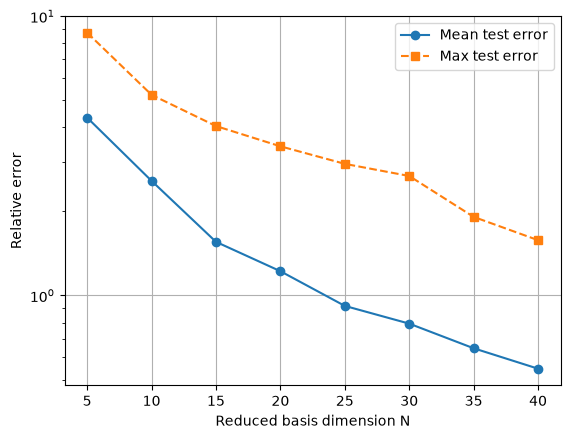

In [441]:
mean_errors = [
    results[N]["mean_error"]
    for N in N_values
]

max_errors = [
    results[N]["max_error"]
    for N in N_values
]

plt.figure()

plt.semilogy(
    N_values,
    mean_errors,
    "o-",
    label="Mean test error"
)

plt.semilogy(
    N_values,
    max_errors,
    "s--",
    label="Max test error"
)

plt.xlabel("Reduced basis dimension N")
plt.ylabel("Relative error")
plt.grid(True)
plt.legend()
plt.show()

**Distribuzione degli errori.** Scegliamo `Nstar=20` e rappresentiamo l'istogramma degli errori percentuali. La distribuzione permette di individuare campioni più difficili che la sola media può nascondere. Impostare `Nstar` seleziona i risultati già salvati, senza ricostruire il solver attivo.

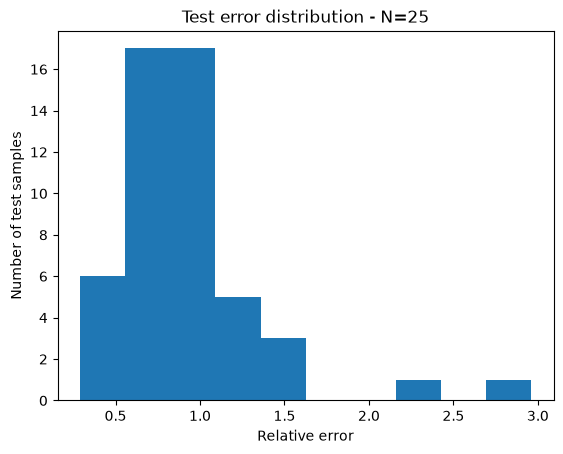

: 

In [ ]:
Nstar = 25   # da decidere DOPO aver visto i risultati

errors = results[Nstar]["errors"]

plt.figure()
plt.hist(errors, bins=10)
plt.xlabel("Relative error")
plt.ylabel("Number of test samples")
plt.title(f"Test error distribution - N={Nstar}")
plt.show()

**Costo online.** Convertiamo i tempi medi in millisecondi e li confrontiamo al variare di $N$. La soluzione di un sistema denso costa tipicamente $O(N^3)$, mentre la ricostruzione $V_Na_N$ costa $O(N_hN)$. Su operazioni molto brevi le oscillazioni dei tempi possono dipendere anche dal rumore di misura.

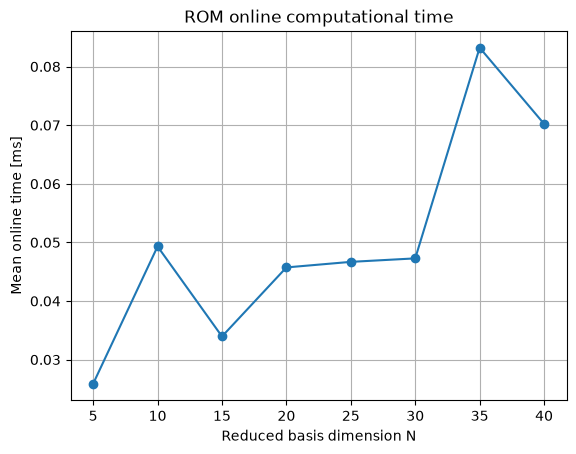

In [443]:
mean_times_ms = np.array([
    results[N]["mean_time"]
    for N in N_values
]) * 1000

plt.figure()

plt.plot(
    N_values,
    mean_times_ms,
    "o-"
)

plt.xlabel("Reduced basis dimension N")
plt.ylabel("Mean online time [ms]")
plt.title("ROM online computational time")
plt.grid(True)

plt.show()

## Optimization Problem

### Obiettivo dell'ottimizzazione

Definiamo il problema $\min_{\mu\in[-5,5]^3}J_N(\mu)$, con $J_N(\mu)=u_N(x_0;\mu)$: cerchiamo i parametri dei tre cilindri che minimizzano la concentrazione nel punto scelto. La valutazione FEM interpola il campo discreto nel punto, che non deve coincidere con un nodo.

La funzione usa il `RBsolver` attivo, quindi la dimensione del ROM dipende dall'ultima costruzione eseguita. Minimizzare una concentrazione puntuale descrive un obiettivo locale; non misura da solo l'omogeneità della concentrazione nell'intero dominio.

In [444]:
from fenics import Point

x0 = Point(1.5, 0.25)

def objective(mu):
    u_rom = RBsolver(mu)

    u_fun = fe.asfunction(u_rom, mixer.Vh)

    return u_fun(x0)

**Valore di riferimento.** Valutiamo l’obiettivo in $\mu=(0,0,0)$, corrispondente ai contributi nulli dei tre cilindri e al flusso di ingresso ancora presente. È un controllo iniziale del solver e un riferimento per confrontare i valori ottenuti dall’ottimizzazione.

In [445]:
mu = np.array([0.0, 0.0, 0.0])

print("J(mu) =", objective(mu))

J(mu) = 0.5166040277682944


**Ottimizzazione locale con Nelder–Mead.** Avviamo la ricerca dal centro del dominio. Il metodo modifica un simplesso nello spazio dei parametri tramite valutazioni dell'obiettivo, senza richiedere derivate. I bounds limitano i parametri a $[-5,5]^3$; `xatol` e `fatol` controllano l'arresto in termini di dispersione dei vertici e dei valori dell'obiettivo, mentre `maxiter` limita le iterazioni. La convergenza non certifica il minimo globale.

In [446]:
from scipy.optimize import minimize

bounds = [
    (-5, 5),
    (-5, 5),
    (-5, 5)
]

mu0 = np.array([0.0, 0.0, 0.0])

result = minimize(
    objective,
    mu0,
    method="Nelder-Mead",
    bounds=bounds,
    options={
        "maxiter": 500,
        "xatol": 1e-6,
        "fatol": 1e-8
    }
)

**Esito della ricerca locale.** Leggiamo lo stato di arresto, il parametro candidato, il valore dell’obiettivo ROM e il numero di valutazioni. `success` indica il soddisfacimento dei criteri del metodo; non certifica né l’ottimalità globale né l’accuratezza rispetto al FOM.

In [447]:
print("Success:", result.success)
print("Message:", result.message)

print("Optimal mu:", result.x)
print("ROM minimum:", result.fun)
print("Function evaluations:", result.nfev)

Success: True
Message: Optimization terminated successfully.
Optimal mu: [-0.96337684  1.05507648 -0.42443475]
ROM minimum: 0.4664095928157056
Function evaluations: 389


**Ricerca multistart.** Ripetiamo Nelder–Mead da 20 punti casuali e dal centro, selezionando il risultato con obiettivo più basso. Partenze differenti aiutano a esplorare diversi bacini di attrazione, senza garantire il minimo globale. Il codice confronta tutti i risultati, anche quelli eventualmente arrestati senza successo: lo stato del candidato selezionato va quindi controllato.

In [448]:
rng = np.random.default_rng(42)

starts = rng.uniform(
    low=-5,
    high=5,
    size=(20, 3)
)

# includiamo anche il centro
starts = np.vstack([
    np.zeros(3),
    starts
])

solutions = []

for mu0 in starts:

    res = minimize(
        objective,
        mu0,
        method="Nelder-Mead",
        bounds=bounds,
        options={
            "maxiter": 500,
            "xatol": 1e-6,
            "fatol": 1e-8
        }
    )

    solutions.append(res)

best = min(
    solutions,
    key=lambda r: r.fun
)

print("Best mu:", best.x)
print("Best ROM objective:", best.fun)
print("Success:", best.success)

Best mu: [-1.18975471 -5.         -4.87877719]
Best ROM objective: 0.4099112553792079
Success: True


**Valutazione dei modi nel punto di interesse.** Precalcoliamo $u_s(x_0)$ e $\phi_i(x_0)$ per le colonne della base globale `V`. Per linearità della ricostruzione FEM si può scrivere $J_N(\mu)=u_s(x_0)+\sum_{i=1}^{N}\phi_i(x_0)a_i(\mu)$.

Il vettore delle valutazioni deve appartenere alla stessa base dei coefficienti. Usiamo `V.shape[1]` per contarne le colonne. La factory attuale valuta invece il campo completo, quindi questi valori servono come preparazione e controllo della formula modale.

In [449]:
x0 = Point(1.5, 0.25)

u_special_fun = fe.asfunction(
    u_special,
    mixer.Vh
)

u_special_x0 = u_special_fun(x0)

# Usiamo la dimensione effettiva della base, indipendente dal valore globale di N.
n_modes = V.shape[1]
phi_x0 = np.zeros(n_modes)

for i in range(n_modes):

    phi_fun = fe.asfunction(
        V[:, i],
        mixer.Vh
    )

    phi_x0[i] = phi_fun(x0)

**Ricostruzione delle funzioni con dimensioni coerenti.** Usiamo il numero effettivo di colonne di `V` per generare insieme solver, coefficienti e obiettivo. La factory usa i primi `N_rom` modi di `U_pod`, coerenti con la costruzione di `V` nel notebook. Se il ROM cambia rispetto a quello ottimizzato in precedenza, `best` resta il vecchio candidato: occorre ripetere la ricerca per ottenere un ottimo del nuovo obiettivo.

In [450]:
# Costruiamo tutte le funzioni dalla stessa base, evitando matrici globali obsolete.
N_rom = V.shape[1]
RBsolver, RBcoefficients, objective = build_ROM(N_rom)


**Validazione FOM del candidato.** Risolviamo il modello completo in `best.x` e confrontiamo $J_h(\mu_*)$ con $J_N(\mu_*)$, calcolando l'errore assoluto $|J_h-J_N|$. Si tratta della validazione della quantità di interesse allo stesso parametro, non di una ricerca del minimo FOM. Se `best` proviene da un'altra dimensione ridotta, il parametro è un candidato precedente.

In [451]:
mu_opt = best.x

u_fom_opt = mixer.FOMsolver(mu_opt)

u_fom_fun = fe.asfunction(
    u_fom_opt,
    mixer.Vh
)

J_fom = u_fom_fun(x0)

J_rom = objective(mu_opt)

print("Optimal parameters:")
print(mu_opt)

print("\nROM objective:")
print(J_rom)

print("\nFOM objective:")
print(J_fom)

print("\nAbsolute output error:")
print(abs(J_fom - J_rom))

Optimal parameters:
[-1.18975471 -5.         -4.87877719]

ROM objective:
0.39813165121776417

FOM objective:
0.4136196469405497

Absolute output error:
0.01548799572278553


**Ottimizzazione e dimensione della base.** Ripetiamo il multistart per diversi $N$ e validiamo ogni candidato con il FOM. Confrontiamo parametri trovati, obiettivo ROM, obiettivo FOM e $|J_h-J_N|/|J_h|$. La divisione richiede $J_h\ne0$ ed è sensibile a valori prossimi a zero. Questa analisi mostra come l'approssimazione del modello influenzi le decisioni, ma non certifica l'ottimo FOM.

In [452]:
N_values_opt = [10, 15, 20, 25, 30, 35, 40]

optimization_results = []

for N in N_values_opt:

    # costruisci ROM per questa N
    # deve restituire coefficients/solver/objective coerenti con V[:, :N]
    RBsolver, RBcoefficients, objective = build_ROM(N)

    solutions = []

    for mu0 in starts:
        res = minimize(
            objective,
            mu0,
            method="Nelder-Mead",
            bounds=bounds,
            options={
                "maxiter": 500,
                "xatol": 1e-6,
                "fatol": 1e-8
            }
        )
        solutions.append(res)

    best = min(solutions, key=lambda r: r.fun)

    mu_opt = best.x
    J_rom = best.fun

    # FOM validation at ROM optimum
    u_fom = mixer.FOMsolver(mu_opt)
    u_fom_fun = fe.asfunction(u_fom, mixer.Vh)
    J_fom = u_fom_fun(x0)

    output_error = abs(J_fom - J_rom)
    relative_output_error = output_error / abs(J_fom)

    optimization_results.append(
        [N, mu_opt, J_rom, J_fom,
         output_error, relative_output_error]
    )

    print(
        f"N={N:2d} | "
        f"mu*={np.round(mu_opt, 3)} | "
        f"ROM={J_rom:.5f} | "
        f"FOM={J_fom:.5f} | "
        f"rel.err={100*relative_output_error:.2f}%"
    )

N=10 | mu*=[-1.696  4.651 -5.   ] | ROM=0.38677 | FOM=0.45048 | rel.err=14.14%
N=15 | mu*=[-1.212  5.    -3.874] | ROM=0.41422 | FOM=0.45549 | rel.err=9.06%
N=20 | mu*=[-1.111 -5.    -4.891] | ROM=0.39771 | FOM=0.41327 | rel.err=3.77%
N=25 | mu*=[-1.161 -5.    -3.78 ] | ROM=0.40776 | FOM=0.42404 | rel.err=3.84%
N=30 | mu*=[-1.249 -5.    -4.389] | ROM=0.38340 | FOM=0.41885 | rel.err=8.46%
N=35 | mu*=[-1.242 -2.49  -5.   ] | ROM=0.40371 | FOM=0.43015 | rel.err=6.15%
N=40 | mu*=[-1.19  -5.    -4.879] | ROM=0.40991 | FOM=0.41362 | rel.err=0.90%


**Ricerca con differential evolution.** Usiamo un ROM da 40 modi e un algoritmo a popolazione che esplora il dominio attraverso mutazione, ricombinazione e selezione. `seed` rende riproducibile la componente casuale; `tol` controlla un criterio di arresto della popolazione e `polish=True` applica un raffinamento locale finale. L'esplorazione è più ampia di una singola ricerca locale, ma non costituisce una prova di ottimalità globale.

In [453]:
from scipy.optimize import differential_evolution

N = 40

RBsolver, RBcoefficients, objective = build_ROM(N)

bounds = [
    (-5, 5),
    (-5, 5),
    (-5, 5)
]

result = differential_evolution(
    objective,
    bounds=bounds,
    seed=42,
    tol=1e-8,
    polish=True
)

print("mu* =", result.x)
print("J_ROM =", result.fun)
print("nfev =", result.nfev)

mu* = [-1.18970245 -4.99999998 -4.8789443 ]
J_ROM = 0.40991125585275573
nfev = 2749


**Verifica del candidato di differential evolution.** Valutiamo il FOM nel parametro restituito dall'algoritmo e confrontiamo la concentrazione puntuale con l'obiettivo ROM. L'errore relativo percentuale è $100|J_N-J_h|/|J_h|$, definito se $J_h\ne0$. Questo controllo riguarda la fedeltà del ROM nel candidato trovato.

In [454]:
mu_opt = result.x

u_fom = mixer.FOMsolver(mu_opt)
u_fom_fun = fe.asfunction(u_fom, mixer.Vh)

J_fom = u_fom_fun(x0)

print("J_ROM =", result.fun)
print("J_FOM =", J_fom)
print(
    "Relative error =",
    100 * abs(result.fun - J_fom) / abs(J_fom),
    "%"
)

J_ROM = 0.40991125585275573
J_FOM = 0.4136178727804472
Relative error = 0.8961452518419065 %


**Confronto con il dataset disponibile.** Valutiamo la quantità di interesse per ogni snapshot FOM di test e selezioniamo il valore minimo. È il migliore tra i campioni disponibili, utile come riferimento indipendente dal ROM; il minimo sul dominio continuo può essere più basso.

In [455]:
J_test = np.zeros(Ntest)

for j in range(Ntest):
    u_fun = fe.asfunction(U_test[:, j], mixer.Vh)
    J_test[j] = u_fun(x0)

j_best = np.argmin(J_test)

print("Best existing FOM test sample:")
print("mu =", mu_test[j_best])
print("J_FOM =", J_test[j_best])

Best existing FOM test sample:
mu = [-2.71296545 -3.62325535 -0.75628861]
J_FOM = 0.5673814835092267


### Diagnosi su un parametro fissato

Ricalcoliamo il FOM in `mu_old` e confrontiamo la quantità di interesse dei ROM di varie dimensioni allo stesso parametro. Tenere fisso $\mu$ separa l'effetto della dimensione ridotta dallo spostamento del candidato ottimo. L'errore puntuale può evolvere diversamente dall'errore globale del campo.

In [456]:
mu_old = np.array([
    -1.18975471,
    -5.0,
    -4.87877719
])

u_fom_old = mixer.FOMsolver(mu_old)
u_fom_old_fun = fe.asfunction(u_fom_old, mixer.Vh)
J_fom_old = u_fom_old_fun(x0)

print(f"FOM: {J_fom_old:.8f}")

for N in [10, 15, 20, 25, 30, 35, 40]:

    RBsolver, RBcoefficients, objective = build_ROM(N)

    J_rom = objective(mu_old)

    error = abs(J_rom - J_fom_old) / abs(J_fom_old)

    print(
        f"N={N:2d} | "
        f"ROM={J_rom:.8f} | "
        f"error={100*error:.2f}%"
    )

FOM: 0.41361965
N=10 | ROM=0.46993220 | error=13.61%
N=15 | ROM=0.44013605 | error=6.41%
N=20 | ROM=0.39813165 | error=3.74%
N=25 | ROM=0.41701521 | error=0.82%
N=30 | ROM=0.38458281 | error=7.02%
N=35 | ROM=0.41463779 | error=0.25%
N=40 | ROM=0.40991126 | error=0.90%


**Copertura del training.** Cerchiamo lo snapshot più vicino a `mu_bad` mediante distanza euclidea nello spazio dei parametri. Poiché i tre parametri hanno lo stesso intervallo, questa misura li tratta sulla stessa scala. La vicinanza indica la copertura locale del campionamento, ma non fornisce da sola una stima dell'errore del ROM.

In [457]:
mu_bad = np.array([-1.18975471, -5.0, -4.87877719])

distances = np.linalg.norm(mu_train - mu_bad, axis=1)

idx = np.argmin(distances)

print("Closest training sample:")
print(mu_train[idx])

print("Distance:", distances[idx])

print("FOM QoI of closest sample:")

u_closest = U_train[:, idx]
u_fun = fe.asfunction(u_closest, mixer.Vh)

print(u_fun(x0))

Closest training sample:
[-4.09007719 -3.8741596  -4.985353  ]
Distance: 3.1129962210243325
FOM QoI of closest sample:
0.6005479099918347


**Vicinato del parametro.** Ordiniamo le distanze e mostriamo i cinque parametri di training più vicini. Questo aiuta a capire se la regione studiata è rappresentata da più snapshot o è scarsamente campionata.

In [458]:
idxs = np.argsort(distances)[:5]

for idx in idxs:
    print(
        np.round(mu_train[idx], 3),
        "distance =",
        round(distances[idx], 3)
    )

[-4.09  -3.874 -4.985] distance = 3.113
[ 1.482 -3.634 -3.985] distance = 3.131
[-1.934 -3.487 -1.967] distance = 3.365
[ 0.651 -1.794 -4.465] distance = 3.72
[ 0.37  -1.939 -1.489] distance = 4.826


**Errore di rappresentazione della base POD.** Proiettiamo la soluzione FOM omogenea sulla base: $a_{proj}=V^Tw_h$, $u_{proj}=u_s+VV^Tw_h$. Per $V^TV=I$, questa è la migliore approssimazione nella norma euclidea dei coefficienti all'interno dello spazio affine $u_s+\operatorname{span}(V)$.

Confrontiamo l'errore sul campo e sulla quantità puntuale. La proiezione minimizza l'errore euclideo globale, non quello nel punto $x_0$; un piccolo errore globale può quindi accompagnarsi a un errore relativo puntuale significativo.

In [459]:
N = 40
V = U_pod[:, :N]

w_bad = u_fom_old - u_special

w_bad_proj = V @ (V.T @ w_bad)

u_bad_proj = u_special + w_bad_proj

projection_error = (
    np.linalg.norm(u_fom_old - u_bad_proj)
    / np.linalg.norm(u_fom_old)
)

u_proj_fun = fe.asfunction(u_bad_proj, mixer.Vh)
J_proj = u_proj_fun(x0)

print(
    f"Full-field projection error: "
    f"{100*projection_error:.3f}%"
)

print("FOM QoI:", J_fom_old)
print("Best POD projection QoI:", J_proj)

print(
    "QoI projection error:",
    100 * abs(J_proj-J_fom_old) / abs(J_fom_old),
    "%"
)

Full-field projection error: 0.791%
FOM QoI: 0.4136196469724894
Best POD projection QoI: 0.4100154715518641
QoI projection error: 0.8713743283246456 %


**Consistenza delle equazioni proiettate.** Assembliamo $A(\mu)$ e calcoliamo $V^Tr_h$, con $r_h=A(\mu)w_h+A(\mu)u_s=A(\mu)u_h$. Il termine di sorgente volumetrico è nullo nel modello corrente.

Gli operatori affini sono assemblati prima dell'imposizione delle condizioni di Dirichlet: il residuo completo può essere non nullo sulle righe vincolate. La sua proiezione dovrebbe essere piccola se i modi hanno valori nulli su quei DOF e assemblaggio e lifting sono coerenti. Una norma piccola verifica la consistenza, ma non certifica l'accuratezza del ROM.

In [460]:
mu_bad = np.array([
    -1.18975471,
    -5.0,
    -4.87877719
])

c1, c2, c3 = mu_bad

A_mu = (
    A0
    + c1*A1
    + c2*A2
    + c3*A3
)

w_fom = u_fom_old - u_special

residual = A_mu @ w_fom + A_mu @ u_special

projected_residual = V.T @ residual

print(
    "||V.T @ residual|| =",
    np.linalg.norm(projected_residual)
)

||V.T @ residual|| = 2.238345244895318e-17


**Coefficienti di proiezione e Galerkin.** Confrontiamo $a_{proj}=V^Tw_h$ con i coefficienti $a_{gal}$ ottenuti dalle equazioni ridotte. Il primo minimizza la distanza euclidea dal FOM; il secondo impone l'ortogonalità del residuo rispetto ai test ridotti. L'operatore di advezione–diffusione non è in generale simmetrico, quindi i due coefficienti non devono coincidere. Il confronto richiede che `V` e `RBcoefficients` usino la stessa base e dimensione.

In [461]:
a_proj = V.T @ w_fom
a_gal = RBcoefficients(mu_bad)
print(
    "Coefficient relative difference:",
    np.linalg.norm(a_proj - a_gal)
    / np.linalg.norm(a_proj)
)

Coefficient relative difference: 0.06074927086368736


**Rappresentazione e soluzione ridotta.** Confrontiamo l'errore del ROM Galerkin con quello della proiezione FOM precedentemente calcolata. A parità di base, la proiezione è il riferimento ottimale in norma euclidea: un divario grande suggerisce di analizzare stabilità e formulazione del sistema ridotto. La cella presuppone che `projection_error` sia stato calcolato nello stesso spazio a 40 modi.

In [462]:
N = 40
RBsolver, RBcoefficients, objective = build_ROM(N)

u_rom_bad = RBsolver(mu_bad)

galerkin_error = (
    np.linalg.norm(u_fom_old - u_rom_bad)
    / np.linalg.norm(u_fom_old)
)

print(
    f"Projection field error: {100*projection_error:.3f}%"
)
print(
    f"Galerkin field error:    {100*galerkin_error:.3f}%"
)

Projection field error: 0.791%
Galerkin field error:    1.419%


**Controllo completo sul parametro critico.** Ricalcoliamo FOM e ROM da 40 modi allo stesso parametro, confrontando errore globale e puntuale. Verifichiamo inoltre che `objective(mu_check)` coincida con la valutazione FEM diretta del campo ROM. L'accordo tra queste due valutazioni controlla l'implementazione dell'obiettivo; l'accordo con il FOM controlla invece l'approssimazione del modello.

In [463]:
import numpy as np
from fenics import Point

# ------------------------------------------------------------
# 1. Punto che aveva mostrato il problema
# ------------------------------------------------------------

mu_check = np.array([
    -1.18975471,
    -5.0,
    -4.87877719
])

x0 = Point(1.5, 0.25)

N = 40


# ------------------------------------------------------------
# 2. Ricostruiamo il ROM N=40
# ------------------------------------------------------------

RBsolver, RBcoefficients, objective = build_ROM(N)


# ------------------------------------------------------------
# 3. Risolviamo NUOVAMENTE FOM e ROM
# ------------------------------------------------------------

u_fom_check = mixer.FOMsolver(mu_check)
u_rom_check = RBsolver(mu_check)


# ------------------------------------------------------------
# 4. Valutiamo entrambe le soluzioni in x0
# ------------------------------------------------------------

u_fom_fun = fe.asfunction(u_fom_check, mixer.Vh)
u_rom_fun = fe.asfunction(u_rom_check, mixer.Vh)

J_fom = u_fom_fun(x0)
J_rom_direct = u_rom_fun(x0)

# Valutazione tramite objective(), per verificare che coincida
J_rom_objective = objective(mu_check)


# ------------------------------------------------------------
# 5. Errori sulla QoI
# ------------------------------------------------------------

abs_qoi_error = abs(J_rom_direct - J_fom)

rel_qoi_error = (
    abs_qoi_error / abs(J_fom)
)


# ------------------------------------------------------------
# 6. Errore globale sul campo
# ------------------------------------------------------------

field_error = (
    np.linalg.norm(u_fom_check - u_rom_check)
    / np.linalg.norm(u_fom_check)
)


# ------------------------------------------------------------
# 7. Stampiamo tutto
# ------------------------------------------------------------

print("mu =", mu_check)

print("\n--- QoI at x0 ---")
print(f"FOM                = {J_fom:.10f}")
print(f"ROM direct         = {J_rom_direct:.10f}")
print(f"ROM objective()    = {J_rom_objective:.10f}")

print("\n--- Consistency check ---")
print(
    "direct vs objective =",
    abs(J_rom_direct - J_rom_objective)
)

print("\n--- Errors ---")
print(f"Absolute QoI error = {abs_qoi_error:.10f}")
print(f"Relative QoI error = {100*rel_qoi_error:.3f}%")
print(f"Global field error = {100*field_error:.3f}%")

mu = [-1.18975471 -5.         -4.87877719]

--- QoI at x0 ---
FOM                = 0.4136196470
ROM direct         = 0.4099112554
ROM objective()    = 0.4099112554

--- Consistency check ---
direct vs objective = 0.0

--- Errors ---
Absolute QoI error = 0.0037083916
Relative QoI error = 0.897%
Global field error = 1.419%


**Verifica della ricostruzione modale dell'obiettivo.** Confrontiamo tre valutazioni: interpolazione del campo ricostruito, somma $u_s(x_0)+\phi(x_0)^Ta_N$ e funzione `objective`. Con gli stessi coefficienti, base e punto, le tre espressioni devono coincidere entro gli errori numerici. Il lifting deve essere incluso anche nella valutazione puntuale.

In [464]:
N = 40

RBsolver, RBcoefficients, objective = build_ROM(N)

V = U_pod[:, :N]

aN = RBcoefficients(mu_check)

# Ricostruzione completa
u_rom = u_special + V @ aN
u_rom_fun = fe.asfunction(u_rom, mixer.Vh)

J_direct = u_rom_fun(x0)

# Valore della lifting solution
u_special_fun = fe.asfunction(u_special, mixer.Vh)
J_special = u_special_fun(x0)

# Valutazione dei singoli modi in x0
phi_x0_check = np.zeros(N)

for i in range(N):
    phi_fun = fe.asfunction(V[:, i], mixer.Vh)
    phi_x0_check[i] = phi_fun(x0)

# Ricostruzione manuale della QoI
J_manual = J_special + phi_x0_check @ aN

print("u_special(x0) =", J_special)
print("modal contribution =", phi_x0_check @ aN)

print()
print("J direct    =", J_direct)
print("J manual    =", J_manual)
print("J objective =", objective(mu_check))

print()
print("manual-direct difference =",
      abs(J_manual - J_direct))

u_special(x0) = 0.5166040277682944
modal contribution = 0.02020974639255554

J direct    = 0.4099112553792078
J manual    = 0.53681377416085
J objective = 0.4099112553792078

manual-direct difference = 0.12690251878164216


**Controllo finale della factory.** Ricostruiamo il ROM da 40 modi e confrontiamo nuovamente la valutazione diretta del campo e l’obiettivo restituito dalla factory. Una differenza prossima alla precisione numerica conferma la coerenza tra le due modalità di valutazione.

In [465]:
N = 40

RBsolver, RBcoefficients, objective = build_ROM(N)

u_rom = RBsolver(mu_check)
u_rom_fun = fe.asfunction(u_rom, mixer.Vh)

J_direct = u_rom_fun(x0)
J_objective = objective(mu_check)

print("J direct    =", J_direct)
print("J objective =", J_objective)
print("difference  =", abs(J_direct - J_objective))

J direct    = 0.4099112553792078
J objective = 0.4099112553792078
difference  = 0.0
